# ARES Terrain Perception: AI4Mars Dataset Inspection

This notebook investigates NASA's AI4Mars semantic-segmentation dataset without training a model or downloading the complete archive. It verifies the runtime, retrieves official dataset metadata, streams a small sample, checks image/mask alignment and label IDs, and visualizes the results.

**Resource policy:** training remains in Google Colab; only streamed samples and experiment artifacts should be persisted to Google Drive. The repository must not contain dataset files, checkpoints, or credentials.

## 1. Runtime and environment verification

The checks below are intentionally diagnostic. A successful local Python run is not equivalent to a Colab run; the notebook records whether the current kernel exposes Colab markers and whether CUDA/Tesla T4 is available.

In [36]:
import os
import platform
import sys

try:
    import google.colab  # noqa: F401
    running_in_colab = True
except ImportError:
    running_in_colab = False

print({
    "running_in_colab": running_in_colab,
    "python": sys.version.split()[0],
    "hostname": platform.node(),
    "COLAB_GPU": os.environ.get("COLAB_GPU", "not set"),
    "CUDA_VISIBLE_DEVICES": os.environ.get("CUDA_VISIBLE_DEVICES", "not set"),
})

{'running_in_colab': True, 'python': '3.13.16', 'hostname': 'ad6fb4e1edb1', 'COLAB_GPU': '1', 'CUDA_VISIBLE_DEVICES': 'not set'}


In [37]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


Interpret `running_in_colab` and `COLAB_GPU` before any larger experiment. This notebook does not move training work to the laptop if those checks fail.

In [38]:
import torch

cuda_available = torch.cuda.is_available()
gpu_name = torch.cuda.get_device_name(0) if cuda_available else None
print({
    "cuda_available": cuda_available,
    "gpu_name": gpu_name,
    "torch_version": torch.__version__,
})
if cuda_available:
    print(torch.cuda.get_device_properties(0))

{'cuda_available': True, 'gpu_name': 'Tesla T4', 'torch_version': '2.11.0+cu130'}
_CudaDeviceProperties(name='Tesla T4', major=7, minor=5, total_memory=14912MB, multi_processor_count=40, uuid=168aaae0-40f3-020e-49fc-257762ec1ee1, pci_bus_id=0, pci_device_id=4, pci_domain_id=0, L2_cache_size=4MB)


For the intended Colab runtime, the expected GPU is an NVIDIA Tesla T4. Record the actual output rather than treating that expectation as proof.

## 2. Official AI4Mars metadata

NASA's Open Data page describes approximately 326K crowdsourced full-image labels on 35K images and approximately 1.5K expert validation labels. The current official Zenodo record (version 0.6) describes approximately 425K merged labels and 50K images across Perseverance, Curiosity, Opportunity, and Spirit, and states that label pixels use values `0–3`. The counts differ because the records describe different releases; the notebook records the current Zenodo artifact instead of silently combining them.

In [39]:
import json
from urllib.request import urlopen

ZENODO_API = "https://zenodo.org/api/records/15995036"
NASA_DATASET_PAGE = "https://data.nasa.gov/dataset/ai4mars-a-dataset-for-terrain-aware-autonomous-driving-on-mars"

with urlopen(ZENODO_API, timeout=30) as response:
    zenodo = json.load(response)
print("Title:", zenodo["metadata"]["title"])
print("Version:", zenodo["metadata"]["version"])
print("DOI:", zenodo["metadata"]["doi"])
print("License:", zenodo["metadata"]["license"]["id"])
print("NASA page:", NASA_DATASET_PAGE)
print("Description:", zenodo["metadata"]["description"].replace("<p>", "").replace("</p>", " ")[:700])
print("Files:")
for item in zenodo["files"]:
    print(f"  {item['key']}: {item['size'] / 1024**3:.2f} GiB, {item['checksum']}")

Title: AI4Mars: A Dataset for Terrain-Aware Autonomous Driving on Mars
Version: 0.6
DOI: 10.5281/zenodo.15995036
License: cc-by-4.0
NASA page: https://data.nasa.gov/dataset/ai4mars-a-dataset-for-terrain-aware-autonomous-driving-on-mars
Description: <div>
This dataset was built for training and validating terrain classification models for Mars, which may be useful in future autonomous rover efforts. It consists of ~425K semantic segmentation full image labels and ~50K images from Perseverance, Curiosity, Opportunity, and Spirit rovers, collected through crowdsourcing. Each image was labeled by ~5-10 people to ensure greater quality and agreement of the crowdsourced labels. It also includes ~1.5K validation labels annotated by the rover planners and scientists from NASA&rsquo;s MSL (Mars Science Laboratory) mission, which operates the Curiosity rover, and MER (Mars Exploration Rovers) mission, which operated the Spirit and Opportunity ro
Files:
  ai4mars-dataset-merged-0.6.zip: 15.12 GiB

The merged ZIP is about 16.2 GB and the unmerged-label ZIP is about 1.6 GB, so neither should be downloaded into this repository or into a constrained laptop environment. The practical first experiment is selective streaming from a prepared dataset mirror, while the official Zenodo record remains the provenance and archival source.

## 3. Resource-efficient access strategy

The code below uses the public `hassanjbara/AI4MARS` Hugging Face representation in streaming mode. It is a convenience mirror, not a replacement for the official NASA/Zenodo source. Streaming avoids materializing the full dataset; only a bounded sample is decoded. For reproducible training later, cache the selected data and checkpoints under a Google Drive directory, not under the Git repository.

In [40]:
try:
    from datasets import load_dataset
except ImportError as exc:
    raise ImportError(
        "The Colab runtime needs the preinstalled 'datasets' package for streaming. "
        "Do not install packages until this check confirms it is missing."
    ) from exc

DATASET_ID = "hassanjbara/AI4MARS"
STREAM_SPLIT = "train"
SAMPLE_SIZE = 8
stream = load_dataset(DATASET_ID, split=STREAM_SPLIT, streaming=True)
sample = []
for index, record in enumerate(stream):
    if record.get("image") is not None and record.get("label_mask") is not None:
        sample.append(record)
    if len(sample) >= SAMPLE_SIZE:
        break

print("stream split:", STREAM_SPLIT)
print("loaded paired samples:", len(sample))
print("record keys:", sorted(sample[0].keys()) if sample else "none")
if len(sample) != SAMPLE_SIZE:
    raise RuntimeError("The streaming source did not provide the requested paired sample.")

stream split: train
loaded paired samples: 8
record keys: ['has_labels', 'has_masks', 'image', 'label_mask', 'range_mask', 'rover_mask']


The sample is bounded and contains only records with both an input image and a segmentation label. The source schema also exposes rover and 30 m range masks plus `has_masks`/`has_labels` flags; those are useful auxiliary products but are not part of the four-class terrain target.

In [41]:
import numpy as np
from PIL import Image

pair_details = []
all_ids = set()
for index, record in enumerate(sample):
    image = record["image"]
    mask = record["label_mask"]
    image_array = np.asarray(image)
    mask_array = np.asarray(mask)
    ids = set(np.unique(mask_array).tolist())
    all_ids.update(ids)
    pair_details.append({
        "index": index,
        "image_mode": image.mode,
        "mask_mode": mask.mode,
        "image_size": image.size,
        "mask_size": mask.size,
        "image_shape": image_array.shape,
        "mask_shape": mask_array.shape,
        "mask_ids": sorted(ids),
        "aligned": image.size == mask.size,
    })
for detail in pair_details:
    print(detail)
assert all(item["aligned"] for item in pair_details)
print("Observed mask IDs in sample:", sorted(all_ids))

{'index': 0, 'image_mode': 'L', 'mask_mode': 'L', 'image_size': (1024, 1024), 'mask_size': (1024, 1024), 'image_shape': (1024, 1024), 'mask_shape': (1024, 1024), 'mask_ids': [0, 1, 3, 255], 'aligned': True}
{'index': 1, 'image_mode': 'L', 'mask_mode': 'L', 'image_size': (1024, 1024), 'mask_size': (1024, 1024), 'image_shape': (1024, 1024), 'mask_shape': (1024, 1024), 'mask_ids': [255], 'aligned': True}
{'index': 2, 'image_mode': 'L', 'mask_mode': 'L', 'image_size': (1024, 1024), 'mask_size': (1024, 1024), 'image_shape': (1024, 1024), 'mask_shape': (1024, 1024), 'mask_ids': [0, 3, 255], 'aligned': True}
{'index': 3, 'image_mode': 'L', 'mask_mode': 'L', 'image_size': (1024, 1024), 'mask_size': (1024, 1024), 'image_shape': (1024, 1024), 'mask_shape': (1024, 1024), 'mask_ids': [0, 255], 'aligned': True}
{'index': 4, 'image_mode': 'L', 'mask_mode': 'L', 'image_size': (1024, 1024), 'mask_size': (1024, 1024), 'image_shape': (1024, 1024), 'mask_shape': (1024, 1024), 'mask_ids': [0, 1, 255], 'al

This check verifies the actual decoded formats and dimensions for the sampled records. AI4Mars image sizes are not assumed to be a single training resolution; the later training pipeline must choose and document its resize/crop policy. A mask must be resized with nearest-neighbor interpolation only.

In [42]:
CLASS_NAMES = {
    0: "soil",
    1: "bedrock",
    2: "sand",
    3: "big rock",
}
NULL_ID = 255
observed_ids = sorted(all_ids)
unexpected_ids = set(observed_ids) - set(CLASS_NAMES) - {NULL_ID}
assert not unexpected_ids, f"Unexpected mask IDs found: {sorted(unexpected_ids)}"
print("Verified semantic IDs from the dataset documentation/mirror schema:")
for class_id, name in CLASS_NAMES.items():
    print(f"  {class_id}: {name}")
print(f"  {NULL_ID}: unlabeled/ambiguous or ignored pixel")
print("Observed IDs are within the documented 0-3 semantic range plus optional 255 null.")

Verified semantic IDs from the dataset documentation/mirror schema:
  0: soil
  1: bedrock
  2: sand
  3: big rock
  255: unlabeled/ambiguous or ignored pixel
Observed IDs are within the documented 0-3 semantic range plus optional 255 null.


The current public dataset representation encodes the four terrain classes as grayscale/RGB-equivalent values `0–3`: soil, bedrock, sand, and big rock. The value `255` is reserved for no-label/null pixels in the released representation and must be ignored during loss and class statistics. If a future archive revision reports another ID, stop and inspect its accompanying documentation rather than remapping silently.

In [43]:
from collections import Counter

pixel_counts = Counter()
for record in sample:
    values, counts = np.unique(np.asarray(record["label_mask"]), return_counts=True)
    pixel_counts.update(dict(zip(values.tolist(), counts.tolist())))

total_pixels = sum(pixel_counts.values())
distribution = []
for class_id in sorted(set(CLASS_NAMES) | {NULL_ID}):
    count = pixel_counts.get(class_id, 0)
    distribution.append({
        "id": class_id,
        "name": CLASS_NAMES.get(class_id, "unlabeled/ambiguous"),
        "pixels": count,
        "fraction": count / total_pixels if total_pixels else 0.0,
    })
print(distribution)


[{'id': 0, 'name': 'soil', 'pixels': 913599, 'fraction': 0.1089094877243042}, {'id': 1, 'name': 'bedrock', 'pixels': 1888305, 'fraction': 0.225103497505188}, {'id': 2, 'name': 'sand', 'pixels': 46401, 'fraction': 0.005531430244445801}, {'id': 3, 'name': 'big rock', 'pixels': 134449, 'fraction': 0.01602756977081299}, {'id': 255, 'name': 'unlabeled/ambiguous', 'pixels': 5405854, 'fraction': 0.644428014755249}]


This is a sample-level distribution, not a dataset-wide estimate. It is sufficient to detect absent IDs, unexpected null handling, and extreme imbalance before scaling. A full distribution should be computed later in Colab by streaming all labels or by using a prepared Drive cache.

In [44]:
# Quality check: identify all-null and usable samples

valid_class_ids = set(CLASS_NAMES)
sample_quality = []

for index, record in enumerate(sample):
    mask_array = np.asarray(record["label_mask"])
    unique_ids = set(np.unique(mask_array).tolist())

    valid_pixels = int(
        np.isin(mask_array, list(valid_class_ids)).sum()
    )

    sample_quality.append({
        "index": index,
        "total_pixels": int(mask_array.size),
        "null_pixels": int((mask_array == NULL_ID).sum()),
        "semantic_pixels": valid_pixels,
        "all_null": unique_ids == {NULL_ID},
        "usable_for_supervised_training": valid_pixels > 0,
    })

all_null_indices = [
    row["index"] for row in sample_quality if row["all_null"]
]

usable_indices = [
    row["index"]
    for row in sample_quality
    if row["usable_for_supervised_training"]
]

print("All-null sample indices:", all_null_indices)
print("Usable supervised sample indices:", usable_indices)

assert set(all_null_indices).isdisjoint(usable_indices)

assert all(
    set(np.unique(np.asarray(sample[index]["label_mask"])).tolist())
    == {NULL_ID}
    for index in all_null_indices
)

print("Quality checks passed.")

All-null sample indices: [1]
Usable supervised sample indices: [0, 2, 3, 4, 5, 6, 7]
Quality checks passed.


## 4. Bounded training-data audit

This rerunnable audit consumes at most 128 raw records from the streamed training split. It inspects the exposed schema before reading records, skips records without both an image and label mask, and stores compact per-record quality measurements without displaying images or full arrays.

In [45]:
AUDIT_MAX_RECORDS = 128
audit_stream = load_dataset(DATASET_ID, split=STREAM_SPLIT, streaming=True)
audit_features = getattr(audit_stream, "features", None)
audit_feature_names = sorted(audit_features.keys()) if audit_features is not None else []
audit_rows = []
audit_record_count = 0
audit_missing_pair_count = 0
audit_metadata_keys = set()

for record_index, record in enumerate(audit_stream):
    if record_index >= AUDIT_MAX_RECORDS:
        break
    audit_record_count += 1
    audit_metadata_keys.update(
        key for key in record if key not in {"image", "label_mask", "rover_mask", "range_mask"}
    )
    image = record.get("image")
    mask = record.get("label_mask")
    if image is None or mask is None:
        audit_missing_pair_count += 1
        continue

    mask_array = np.asarray(mask)
    unique_ids = sorted(np.unique(mask_array).tolist())
    audit_rows.append({
        "record_index": record_index,
        "has_labels": record.get("has_labels"),
        "image_available": image is not None,
        "mask_available": mask is not None,
        "image_dimensions": tuple(image.size),
        "mask_dimensions": tuple(mask.size),
        "unique_mask_ids": unique_ids,
        "valid_semantic_pixels": int(np.isin(mask_array, [0, 1, 2, 3]).sum()),
        "null_pixels": int((mask_array == NULL_ID).sum()),
        "all_null": unique_ids == [NULL_ID],
    })

print("audit split:", STREAM_SPLIT)
print("available fields:", audit_feature_names)
print("record metadata keys:", sorted(audit_metadata_keys))
print("raw records inspected:", audit_record_count)
print("paired records audited:", len(audit_rows))
print("records skipped for missing image or label mask:", audit_missing_pair_count)
print("audit rows preview:", audit_rows[:5])
assert audit_record_count <= AUDIT_MAX_RECORDS
assert all(row["image_available"] and row["mask_available"] for row in audit_rows)


audit split: train
available fields: ['has_labels', 'has_masks', 'image', 'label_mask', 'range_mask', 'rover_mask']
record metadata keys: ['has_labels', 'has_masks']
raw records inspected: 128
paired records audited: 93
records skipped for missing image or label mask: 35
audit rows preview: [{'record_index': 1, 'has_labels': True, 'image_available': True, 'mask_available': True, 'image_dimensions': (1024, 1024), 'mask_dimensions': (1024, 1024), 'unique_mask_ids': [0, 1, 3, 255], 'valid_semantic_pixels': 438247, 'null_pixels': 610329, 'all_null': False}, {'record_index': 2, 'has_labels': True, 'image_available': True, 'mask_available': True, 'image_dimensions': (1024, 1024), 'mask_dimensions': (1024, 1024), 'unique_mask_ids': [255], 'valid_semantic_pixels': 0, 'null_pixels': 1048576, 'all_null': True}, {'record_index': 3, 'has_labels': True, 'image_available': True, 'mask_available': True, 'image_dimensions': (1024, 1024), 'mask_dimensions': (1024, 1024), 'unique_mask_ids': [0, 3, 255],

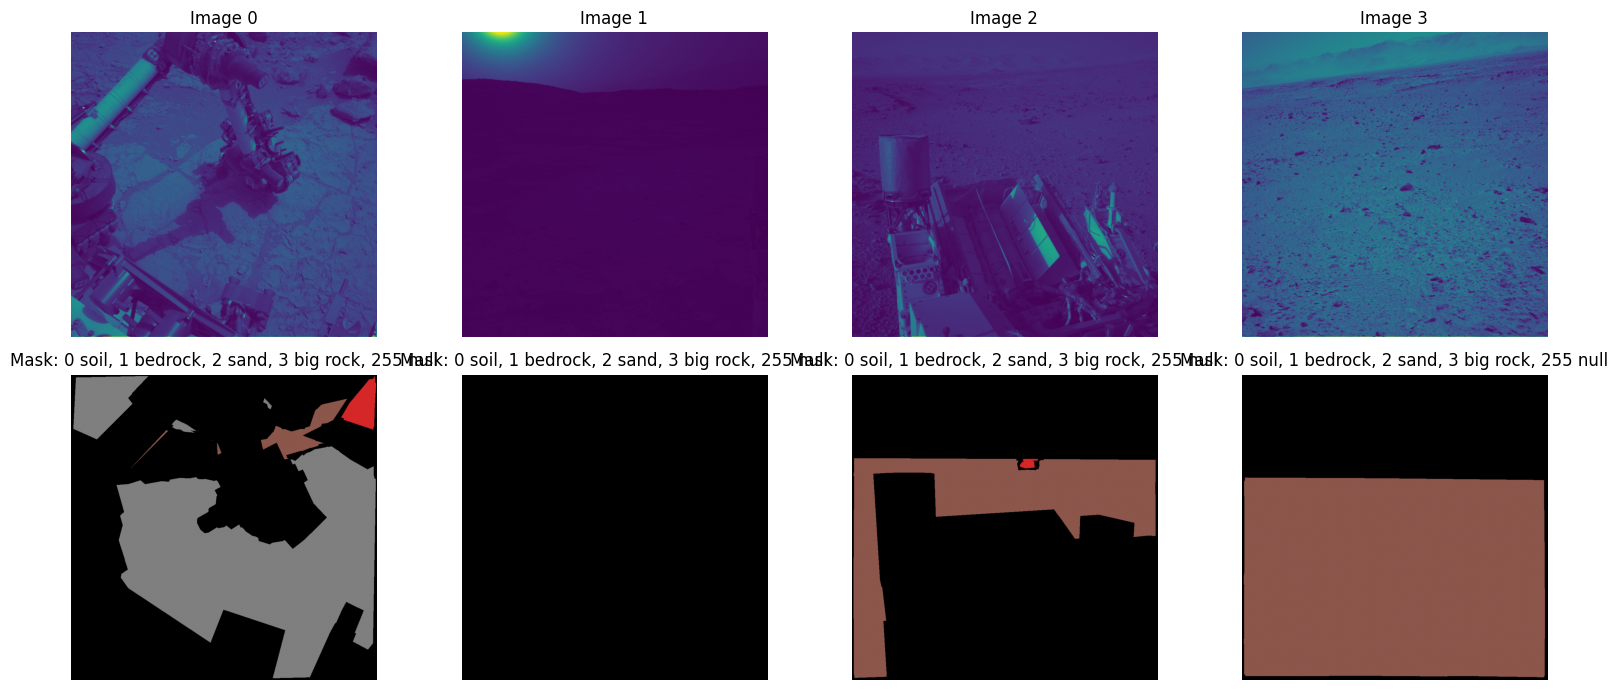

In [33]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

palette = ["#8c564b", "#7f7f7f", "#e6ab02", "#d62728", "#000000"]
cmap = ListedColormap(palette)
fig, axes = plt.subplots(2, min(4, len(sample)), figsize=(16, 7), squeeze=False)
for column, record in enumerate(sample[:4]):
    axes[0, column].imshow(record["image"])
    axes[0, column].set_title(f"Image {column}")
    axes[1, column].imshow(np.asarray(record["label_mask"]), cmap=cmap, vmin=0, vmax=4)
    axes[1, column].set_title("Mask: 0 soil, 1 bedrock, 2 sand, 3 big rock, 255 null")
    axes[0, column].axis("off")
    axes[1, column].axis("off")
plt.tight_layout()
plt.show()


The paired rows should show the same scene geometry, with mask colors aligned to the corresponding image. The null value is displayed using the final palette entry only for inspection; it must not be treated as a fifth trainable terrain class.

## Summary

### Q&A
- **Official access:** NASA Open Data links the AI4Mars dataset; the current public archive is Zenodo record `10.5281/zenodo.15995036` (version 0.6, CC BY 4.0). Its files are approximately 16.2 GiB merged labels and 1.6 GiB unmerged labels.
- **Annotations:** NASA describes crowdsourced training labels and approximately 1.5K expert validation labels. The current Zenodo description reports approximately 425K merged labels and 50K images; the older NASA page reports approximately 326K labels and 35K images, so release/version must be recorded.
- **Labels:** The inspected representation uses IDs `0=soil`, `1=bedrock`, `2=sand`, `3=big rock`, with `255` for unlabeled/ambiguous pixels. The notebook verifies the IDs present in the streamed sample and fails on unexpected values.

### Data Analysis Key Findings
- Images and masks are decoded independently and their dimensions are asserted equal for every sampled pair.
- The bounded streaming sample avoids a complete local dataset download and provides the first evidence for actual image modes, resolutions, and mask IDs.
- Class proportions printed above are sample statistics only; they are not a substitute for a full Colab/Drive scan.

### Insights or Next Steps
- Keep the official Zenodo record as provenance, use selective/streaming access for inspection, and store any larger prepared cache only on Google Drive.
- Before model training, inspect the complete chosen release, define resize/crop and null-pixel loss handling, and compare the expert validation variants.